# Tarea 2 Python

### Integrantes:

- Jorge Miyoshi Mikami Alonso
- Luis Manuel Reyes Colín


## Parte 1

**1) Responde las siguientes preguntas, en cada inciso justifica tus respuestas.**

**a) Menciona dos características de las distribuciones de grado de las siguientes redes**

- **-) Red aleatoria**
- **-) Red de libre escala**

**Red aleatoria.**

1. **Su distribución es binomial (y si la red es grande y dispersa, prácticamente Poisson), con un pico alrededor del grado promedio $\langle k \rangle$.** Como cada arista se pone de forma independiente con probabilidad $p$, el grado de un nodo es básicamente sumar $N-1$ "volados" de Bernoulli: $P(k)=\binom{N-1}{k}p^k(1-p)^{N-1-k}$. O sea, casi todos los nodos tienen un grado parecido a $\langle k\rangle=(N-1)p$, y la red sí tiene una escala característica.
2. **Las colas se caen rapidísimo (más rápido que una exponencial).** Encontrar un nodo con grado mucho mayor que $\langle k\rangle$ es casi imposible, así que no hay _hubs_. La varianza es chiquita y finita ($\sigma^2 \approx \langle k\rangle$ en el límite Poisson), entonces la red es bastante homogénea: todos los nodos se parecen.

**Red de libre escala.**

1. **Sigue una ley de potencias $P(k)\sim k^{-\gamma}$**, normalmente con $2<\gamma<3$ en redes reales. En escala log-log se ve como una recta con pendiente $-\gamma$. Aquí no hay un grado "típico": la distribución se ve igual aunque cambies la escala ($P(\lambda k)\propto P(k)$), y de ahí sale el nombre.
2. **Tiene cola pesada, o sea, hay _hubs_.** La mayoría de los nodos tiene pocos vecinos, pero unos cuantos tienen muchísimos. Para $2<\gamma\le 3$ el segundo momento $\langle k^2\rangle$ diverge cuando $N\to\infty$, así que las fluctuaciones son enormes y el promedio $\langle k \rangle$ no nos dice mucho de cómo es un nodo "normal".

**b) ¿Por qué en la práctica las distribuciones de grado de las redes aleatorias suelen ser aproximadas mediante distribuciones Poisson?**

Porque las redes reales que nos interesan suelen ser **grandes y dispersas**: $N$ es enorme y $p$ es muy chiquita, pero el grado promedio $\langle k\rangle=(N-1)p$ se queda en un valor finito. Y justo en ese límite la binomial se convierte en Poisson (la famosa ley de eventos raros):

$$\binom{N-1}{k}p^k(1-p)^{N-1-k}\;\xrightarrow[N\to\infty,\;p\to 0]{}\; e^{-\langle k\rangle}\frac{\langle k\rangle^k}{k!}.$$

Además, la Poisson es mucho más cómoda de usar: depende de un solo parámetro ($\langle k\rangle$), no depende de $N$ (así podemos comparar redes de tamaños distintos con el mismo grado promedio) y las cuentas salen más fácil. Para $k\ll N$ la diferencia entre las dos es despreciable, así que no perdemos nada.

**c) ¿Es verdad que las redes con distribuciones de grado de Ley de potencias siempre tienen la propiedad de mundo pequeño?**

**No.** La distribución de grado solo nos dice cuántos vecinos tiene cada nodo, pero no _cómo_ están conectados, y el mundo pequeño depende justo de eso. Nuestros argumentos:

- La propiedad de mundo pequeño (como la definen Watts y Strogatz) pide dos cosas: distancias promedio cortas ($\langle d\rangle\sim\ln N$) **y** un coeficiente de agrupamiento alto comparado con una red aleatoria equivalente. El modelo de Barabási–Albert tiene distancias hasta ultracortas ($\langle d\rangle\sim \ln N/\ln\ln N$ para $2<\gamma<3$), pero su agrupamiento se va a cero conforme crece $N$, así que se queda corto en la segunda condición.
- Y aunque solo pidiéramos distancias cortas, es fácil armar contraejemplos. Si juntamos un montón de estrellas desconectadas cuyos tamaños siguen una ley de potencias, la distribución es libre de escala pero la red ni siquiera es conexa (distancias infinitas). También hay redes libres de escala metidas en el espacio (donde solo se conectan nodos cercanos) cuyas distancias crecen como una potencia de $N$ y no como un logaritmo. Y en el modelo de configuración con $\gamma$ grande puede que ni haya componente gigante.

Lo que sí pasa es que muchas redes libres de escala _típicas_ (armadas al azar con esa distribución y $2<\gamma<3$) tienen distancias muy cortas gracias a los _hubs_. Pero eso no es algo que la ley de potencias garantice por sí sola.


## Parte 2

**2) Usando networkx construye una red dirigida pesada de coocurrencias de palabras del siguiente texto y responde las preguntas:**

Para esta actividad hay que considerar estos puntos:

1. Remover las siguientes palabras del texto: the, a, an, of, and, by, may, at
2. La coocurrencia es a un sólo paso, i.e., la frase "envied that kings have" se transforma en la red envied-->that--> kings-->have.

Primero importamos lo que vamos a necesitar. Si no tienen XGI, se instala con `pip install xgi`.


In [1]:
# !pip install xgi networkx matplotlib
import itertools
from collections import Counter

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import xgi

print("networkx", nx.__version__, "| xgi", xgi.__version__)

networkx 3.6.1 | xgi 0.10.2


### Preprocesamiento del texto

Pegamos el texto de la tarea, lo partimos en palabras y le quitamos las que nos pidieron: _the, a, an, of, and, by, may, at_.


In [ ]:
texto = """
the life and adventures of robinson crusoe by daniel defoe with illustrations by h m brock london seeley service co limited great russell street chapter i
start in life i was born in the year in the city of york of a good family though not of that country my father being a foreigner of bremen who settled first at
hull he got a good estate by merchandise and leaving off his trade lived afterwards at york from whence he had married my mother whose relations were
named robinson a very good family in that country and from whom i was called robinson kreutznaer but by the usual corruption of words in england we
are now called nay we call ourselves and write our name crusoe and so my companions always called me i had two elder brothers one of whom was
lieutenant colonel to an english regiment of foot in flanders formerly commanded by the famous colonel lockhart and was killed at the battle near
dunkirk against the spaniards what became of my second brother i never knew any more than my father or mother knew what became of me being the
third son of the family and not bred to any trade my head began to be filled very early with rambling thoughts my father who was very ancient had given
me a competent share of learning as far as house education and a country free school generally go and designed me for the law but i would be satisfied
with nothing but going to sea and my inclination to this led me so strongly against the will nay the commands of my father and against all the entreaties
and persuasions of my mother and other friends that there seemed to be something fatal in that propensity of nature tending directly to the life of misery
which was to befall me my father a wise and grave man gave me serious and excellent counsel against what he foresaw was my design he called me one
morning into his chamber where he was confined by the gout and expostulated very warmly with me upon this subject he asked me what reasons more
than a mere wandering inclination i had for leaving father s house and my native country where i might be well introduced and had a prospect of raising
my fortune by application and industry with a life of ease and pleasure he told me it was men of desperate fortunes on one hand or of aspiring superior
fortunes on the other who went abroad upon adventures to rise by enterprise and make themselves famous in undertakings of a nature out of the
common road that these things were all either too far above me or too far below me that mine was the middle state or what might be called the upper
station of low life which he had found by long experience was the best state in the world the most suited to human happiness not exposed to the miseries
and hardships the labour and sufferings of the mechanic part of mankind and not embarrassed with the pride luxury ambition and envy of the upper part
of mankind he told me i might judge of the happiness of this state by this one thing viz that this was the state of life which all other people envied that
kings have frequently lamented the miserable consequence of being born to great things and wished they had been placed in the middle of the two
extremes between the mean and the great that the wise man gave his testimony to this as the standard of felicity when he prayed to have neither poverty
nor riches he bade me observe it and i should always find that the calamities of life were shared among the upper and lower part of mankind but that the
middle station had the fewest disasters and was not exposed to so many vicissitudes as the higher or lower part of mankind nay they were not subjected
to so many distempers and uneasinesses either of body or mind as those were who by vicious living luxury and extravagances on the one hand or by hard
labour want of necessaries and mean or insufficient diet on the other hand bring distemper upon themselves by the natural consequences of their way of
living that the middle station of life was calculated
"""

stopwords = {"the", "a", "an", "of", "and", "by", "may", "at"}

palabras_originales = texto.split()
palabras = [w for w in palabras_originales if w not in stopwords]

print("Palabras en el texto original:", len(palabras_originales))
print("Palabras después de filtrar:  ", len(palabras))
print(palabras[:20])

Palabras en el texto original: 734
Palabras después de filtrar:   587
['life', 'adventures', 'robinson', 'crusoe', 'daniel', 'defoe', 'with', 'illustrations', 'h', 'm', 'brock', 'london', 'seeley', 'service', 'co', 'limited', 'great', 'russell', 'street', 'chapter']


### Construcción de la red

Como la coocurrencia es a un solo paso, cada palabra apunta a la que sigue en el texto (ya filtrado). El peso de la arista $u\to v$ es cuántas veces aparece el par $(u, v)$ seguido. Metemos los nodos en el orden en que aparecen por primera vez, porque ese orden lo vamos a ocupar después para el vector inicial de Katz.


In [3]:
pares = Counter(zip(palabras[:-1], palabras[1:]))

G = nx.DiGraph()
G.add_nodes_from(dict.fromkeys(palabras))  # nodos en orden de aparición
for (u, v), w in pares.items():
    G.add_edge(u, v, weight=w)

print("Nodos:", G.number_of_nodes())
print("Aristas:", G.number_of_edges())
print("Autolazos:", nx.number_of_selfloops(G))
print("\nAristas con peso > 2:")
for u, v, w in sorted(G.edges(data="weight"), key=lambda x: -x[2]):
    if w > 2:
        print(f"  {u} -> {v}: {w}")

Nodos: 317
Aristas: 547
Autolazos: 0

Aristas con peso > 2:
  my -> father: 5
  part -> mankind: 4


**a) Dibuja la red.**

El tamaño de cada nodo va de acuerdo a su grado pesado total y el grosor de las aristas a su peso. Para que no quede un amontonadero de texto, solo ponemos etiqueta a las palabras con grado pesado total de 8 o más.


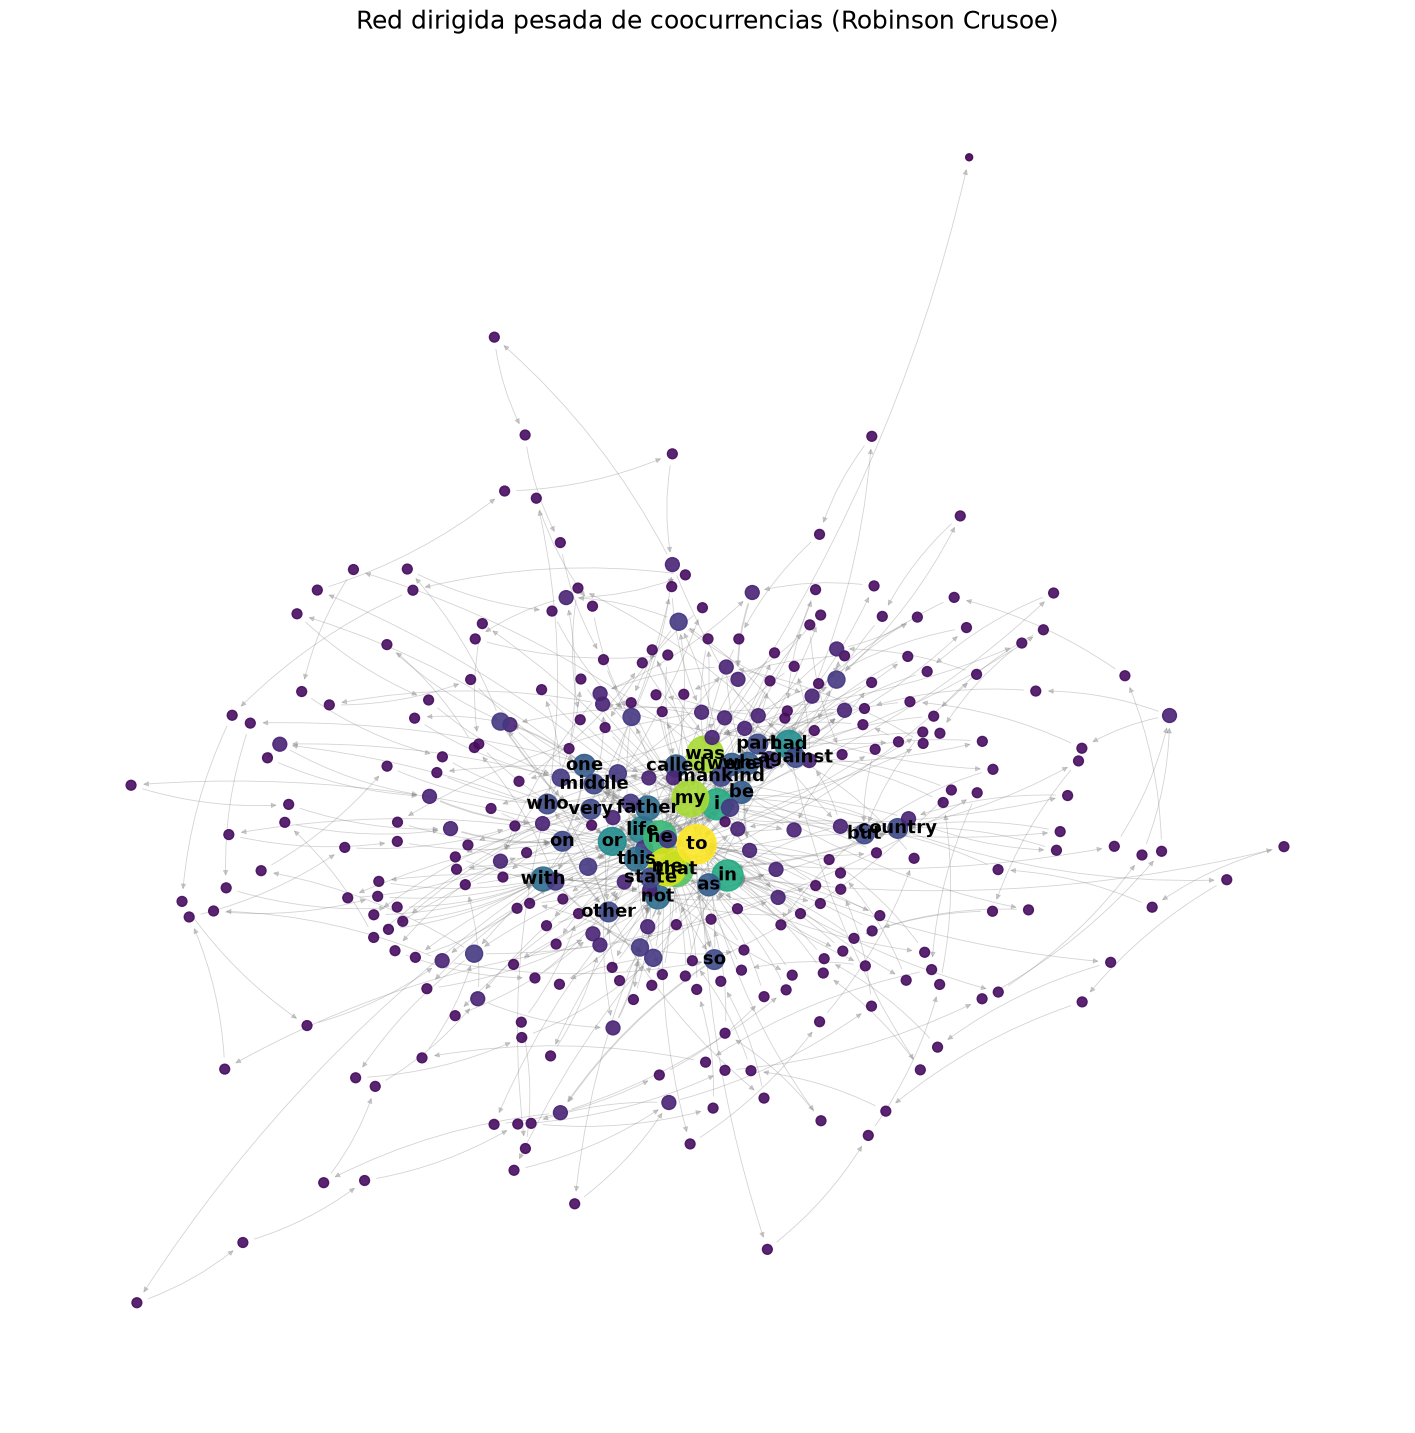

In [4]:
fuerza = dict(G.degree(weight="weight"))
pos = nx.spring_layout(G, k=0.35, iterations=200, seed=42)

fig, ax = plt.subplots(figsize=(18, 18))
nx.draw_networkx_edges(
    G,
    pos,
    ax=ax,
    alpha=0.35,
    arrowsize=8,
    width=[0.6 * G[u][v]["weight"] for u, v in G.edges()],
    edge_color="gray",
    connectionstyle="arc3,rad=0.1",
)
nx.draw_networkx_nodes(
    G,
    pos,
    ax=ax,
    node_size=[25 * fuerza[n] for n in G.nodes()],
    node_color=[fuerza[n] for n in G.nodes()],
    cmap="viridis",
    alpha=0.9,
)
etiquetas = {n: n for n in G.nodes() if fuerza[n] >= 8}
nx.draw_networkx_labels(
    G, pos, labels=etiquetas, font_size=13, font_weight="bold", ax=ax
)
ax.set_title("Red dirigida pesada de coocurrencias (Robinson Crusoe)", fontsize=18)
ax.axis("off")
plt.show()

**b) ¿Cuáles son los cinco nodos con mayor ingrado pesado y exgrado pesado?**


In [5]:
ingrado = sorted(G.in_degree(weight="weight"), key=lambda x: -x[1])
exgrado = sorted(G.out_degree(weight="weight"), key=lambda x: -x[1])

print("Top 5 ingrado pesado:")
for n, d in ingrado[:5]:
    print(f"  {n:6s} {d}")
print("\nTop 5 exgrado pesado:")
for n, d in exgrado[:5]:
    print(f"  {n:6s} {d}")

# Comprobación: ¿en qué nodos difieren ingrado y exgrado?
dif = {
    n: G.in_degree(n, weight="weight") - G.out_degree(n, weight="weight")
    for n in G.nodes()
}
print("\nNodos donde ingrado != exgrado:", {n: d for n, d in dif.items() if d != 0})
print("Primera palabra:", palabras[0], "| Última palabra:", palabras[-1])

Top 5 ingrado pesado:
  to     16
  me     15
  was    14
  my     14
  that   12

Top 5 exgrado pesado:
  to     16
  me     15
  was    14
  my     14
  that   12

Nodos donde ingrado != exgrado: {'life': -1, 'calculated': 1}
Primera palabra: life | Última palabra: calculated


**c) ¿Qué interpretación tienen los resultados del inciso anterior?**

Nos salieron exactamente los mismos cinco nodos, con los mismos valores, en los dos casos: **to (16), me (15), was (14), my (14) y that (12)**. Y no es coincidencia, sale directito de cómo armamos la red. Como el texto es una sola cadena de palabras, cada vez que aparece una palabra recibe una arista de la anterior y manda una a la siguiente. Entonces el ingrado pesado y el exgrado pesado de cada palabra son igualitos a cuántas veces aparece en el texto. Las únicas excepciones son la primera palabra (_life_, con un exgrado de más) y la última (_calculated_, con un ingrado de más). O sea, en esta red los grados pesados son básicamente un conteo de frecuencias.

¿Y qué nos dicen? Que aun quitando _the, a, of, and_, las palabras más repetidas siguen siendo palabras "de relleno" gramatical: la preposición _to_, el pronombre _me_, el auxiliar _was_, el posesivo _my_ y el conector _that_. Son como el pegamento del texto, porque se conectan con un montón de palabras distintas antes y después. Que _me_ y _my_ estén hasta arriba tiene todo el sentido en un relato en primera persona, donde el narrador se la pasa hablando de sí mismo (_my father_, _told me_, _gave me_). Las palabras con más contenido, como _father_, _life_ o _mankind_, aparecen un poco más abajo y nos dan una idea de qué trata el fragmento: los consejos del papá sobre la vida y la "clase media" de la humanidad.


**d) ¿Cuáles son los cinco nodos con mayor centralidad de Katz (considerando los pesos de las aristas) cuando consideras un factor de amortiguación alpha igual a 0.13 y un vector inicial de centralidades crecientes? Donde por vector de centralidades creciente debe entenderse que el nodo 1 tiene centralidad inicial 1, el nodo 2 centralidad inicial 2, y así sucesivamente.**

La centralidad de Katz resuelve $x = \alpha A^{T} x + \beta$, y para que converja necesitamos $\alpha < 1/\lambda_{\max}$. Así que primero checamos eso con la matriz de pesos.

Para el vector $\beta$ tomamos el orden de los nodos en la red, que es el orden en que aparecen por primera vez en el texto: la primera palabra (_life_) tiene $\beta=1$, la segunda (_adventures_) $\beta=2$, y así. Ojo: en networkx, para redes dirigidas la centralidad de Katz de un nodo se acumula con las aristas que le **llegan**.


In [6]:
A = nx.to_numpy_array(G, weight="weight")
lambda_max = max(abs(np.linalg.eigvals(A)))
print(f"lambda_max = {lambda_max:.4f}  ->  1/lambda_max = {1 / lambda_max:.4f}")
print("¿alpha = 0.13 < 1/lambda_max?", 0.13 < 1 / lambda_max)

beta = {n: i + 1 for i, n in enumerate(G.nodes())}
print("\nPrimeros valores de beta:", list(beta.items())[:5])

katz = nx.katz_centrality(G, alpha=0.13, beta=beta, weight="weight", max_iter=10_000)
top_katz = sorted(katz.items(), key=lambda x: -x[1])[:5]

print("\nTop 5 centralidad de Katz (alpha=0.13, beta creciente):")
for n, c in top_katz:
    print(
        f"  {n:8s} katz={c:.4f}  beta={beta[n]:3d}  ingrado pesado={G.in_degree(n, weight='weight')}"
    )

lambda_max = 4.0178  ->  1/lambda_max = 0.2489
¿alpha = 0.13 < 1/lambda_max? True

Primeros valores de beta: [('life', 1), ('adventures', 2), ('robinson', 3), ('crusoe', 4), ('daniel', 5)]

Top 5 centralidad de Katz (alpha=0.13, beta creciente):
  to       katz=0.1297  beta= 91  ingrado pesado=16
  was      katz=0.1230  beta= 24  ingrado pesado=14
  me       katz=0.1225  beta= 84  ingrado pesado=15
  or       katz=0.1141  beta=115  ingrado pesado=8
  this     katz=0.1122  beta=148  ingrado pesado=6


Para entender bien qué tanto mueve las cosas el vector creciente, lo comparamos con la Katz "de siempre", con $\beta=1$ para todos.


In [7]:
katz_unif = nx.katz_centrality(
    G, alpha=0.13, beta=1.0, weight="weight", max_iter=10_000
)
print("Top 5 Katz con beta = 1 (uniforme):")
for n, c in sorted(katz_unif.items(), key=lambda x: -x[1])[:5]:
    print(f"  {n:8s} katz={c:.4f}  beta creciente habría dado beta={beta[n]}")

Top 5 Katz con beta = 1 (uniforme):
  was      katz=0.1752  beta creciente habría dado beta=24
  my       katz=0.1608  beta creciente habría dado beta=35
  to       katz=0.1523  beta creciente habría dado beta=91
  me       katz=0.1464  beta creciente habría dado beta=84
  father   katz=0.1450  beta creciente habría dado beta=36


**e) ¿Qué interpretación tienen los resultados del inciso anterior?**

Con $\alpha=0.13$ y $\lambda_{\max}\approx 4.02$ nos queda $\alpha\lambda_{\max}\approx 0.52<1$, así que todo converge bien. Un camino de longitud $\ell$ pesa más o menos $0.13^\ell$ (por los pesos), entonces la influencia se apaga rápido: lo que más pesa son los vecinos directos y un poquito los de dos pasos.

Los cinco más centrales nos salieron **to, was, me, or, this**, y lo leemos como una mezcla de dos cosas:

- **Lo que les llega por la red:** _to_, _was_ y _me_ están arriba porque son de las que más ingrado pesado tienen (16, 14 y 15). Les llegan muchas aristas, y por cada una se llevan un pedazo de la centralidad del vecino.
- **El sesgo del vector inicial:** como $\beta$ crece con el orden de aparición, las palabras que salen por primera vez ya tarde en el texto arrancan con mucha ventaja, y encima le pasan su $\beta$ grandote a las palabras a las que apuntan. Por eso _or_ ($\beta=115$, ingrado 8) y _this_ ($\beta=148$, ingrado 6) se meten al top 5, y _mankind_ ($\beta=251$) se queda en sexto. En cambio, _was_ tiene $\beta=24$ y aun así queda segunda, lo que nos dice que su lugar se lo ganó por la estructura de la red y no por el sesgo.

Cuando usamos $\beta$ uniforme, el top cambia a _was, my, to, me, father_: se van _or_ y _this_, y entran _my_ y _father_, que aparecen muy al principio del texto y por eso el vector creciente les pegaba. En resumen, el vector creciente funciona como una especie de "importancia de entrada" que favorece a las palabras que llegan tarde a la historia, que en este fragmento son las del sermón del papá sobre los estados de la vida (_this state_, _upper or lower part of mankind_). Las que aparecen en las dos versiones (_to, was, me_) son las realmente sólidas: su centralidad viene de cómo están conectadas.


**f) Transforma las flechas en aristas simples (i.e., quita las direcciones y los pesos); luego mediante el paquete XGI de python dibuja el Complejo cliqué de la red considerando simplices de a lo más dimensión 5.**

Le quitamos direcciones y pesos (la pasamos a `nx.Graph`) y armamos el complejo clique (también le dicen complejo bandera) con `xgi.flag_complex`, limitándolo a simplices de dimensión 5 como máximo (o sea, de a lo más 6 nodos).


In [8]:
H = nx.Graph()
H.add_nodes_from(G.nodes())
H.add_edges_from(G.edges())  # sin direcciones ni pesos
H.remove_edges_from(nx.selfloop_edges(H))

print(
    "Red no dirigida -> nodos:", H.number_of_nodes(), "| aristas:", H.number_of_edges()
)

SC = xgi.flag_complex(H, max_order=5)
conteo = Counter(len(e) - 1 for e in SC.edges.members())
print("\nSimplices en el complejo (por dimensión):")
for dim in range(1, 6):
    print(f"  dimensión {dim}: {conteo.get(dim, 0)}")

# Verificación independiente con networkx: tamaño de todas las cliques
print(
    "\nTamaño de cliques en la red (networkx):",
    Counter(len(c) for c in nx.enumerate_all_cliques(H)),
)

Red no dirigida -> nodos: 317 | aristas: 544

Simplices en el complejo (por dimensión):
  dimensión 1: 544
  dimensión 2: 31
  dimensión 3: 0
  dimensión 4: 0
  dimensión 5: 0

Tamaño de cliques en la red (networkx): Counter({2: 544, 1: 317, 3: 31})


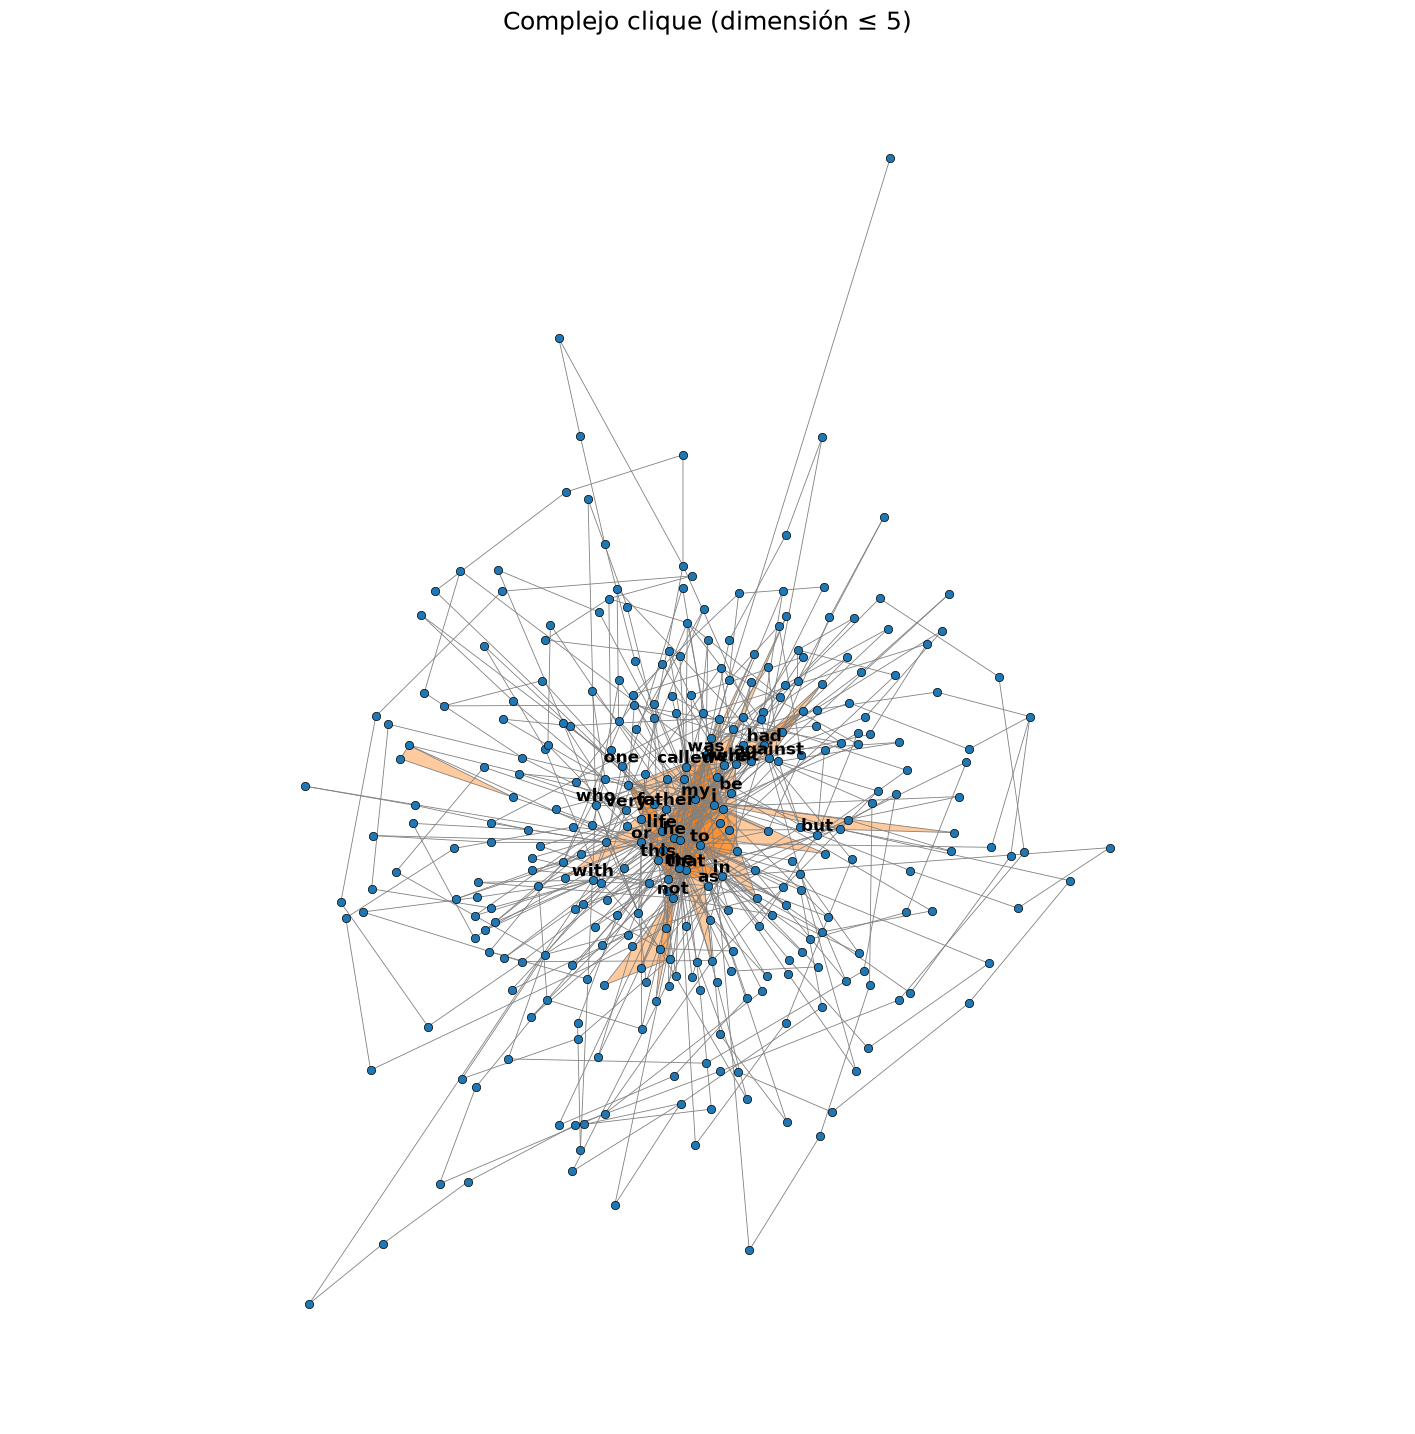

In [9]:
pos_sc = {n: pos[n] for n in SC.nodes}  # reutilizamos el layout del inciso a)

fig, ax = plt.subplots(figsize=(18, 18))
xgi.draw(
    SC,
    pos=pos_sc,
    ax=ax,
    node_size=6,
    node_fc="tab:blue",
    node_lw=0.5,
    dyad_color="gray",
    dyad_lw=0.6,
    edge_fc="tab:orange",
)
grado_H = dict(H.degree())
for n in SC.nodes:
    if grado_H[n] >= 8:
        ax.text(*pos_sc[n], n, fontsize=12, fontweight="bold", ha="center", va="bottom")
ax.set_title("Complejo clique (dimensión ≤ 5)", fontsize=18)
plt.show()

Como la red completa queda bastante amontonada, también dibujamos nada más la parte del complejo que tiene triángulos (2-simplices), para verlos mejor.


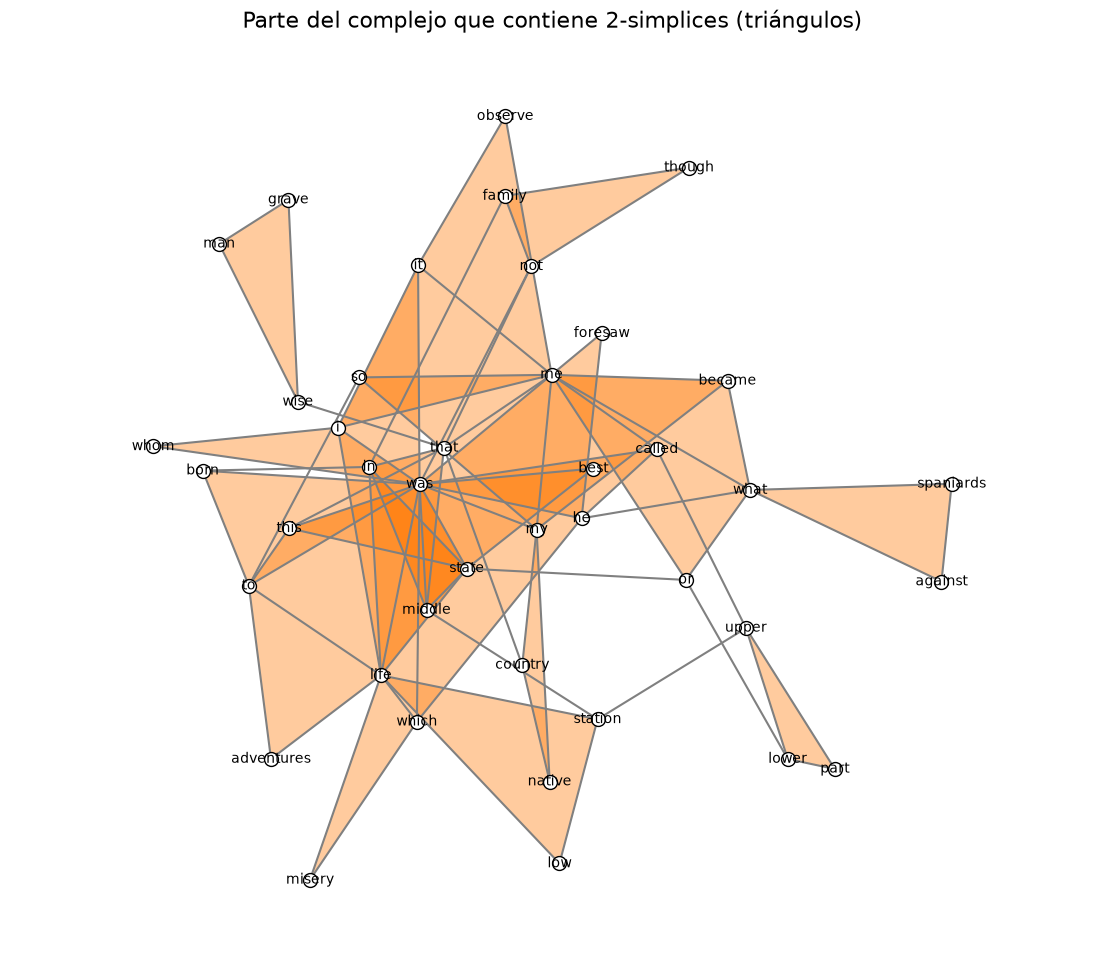

In [10]:
triangulos = [e for e in SC.edges.members() if len(e) == 3]
nodos_tri = set().union(*triangulos)
sub = SC.copy()
sub.remove_nodes_from([n for n in SC.nodes if n not in nodos_tri])

H_sub = H.subgraph(nodos_tri)
pos_sub = nx.spring_layout(H_sub, seed=7, k=0.6)

fig, ax = plt.subplots(figsize=(14, 12))
xgi.draw(
    sub,
    pos=pos_sub,
    ax=ax,
    node_size=10,
    dyad_color="gray",
    edge_fc="tab:orange",
    node_labels=True,
)
ax.set_title("Parte del complejo que contiene 2-simplices (triángulos)", fontsize=16)
plt.show()

**g) Imprime la distribución de grados generalizada de dimensión 3 sobre aristas (i.e., para cada arista ver cuántos tetraedros inciden en ella) y determina las 5 aristas con mayor grado.**

Para cada arista (1-simplex) contamos cuántos tetraedros (3-simplices, 4 nodos) la contienen. Hicimos una función general que, para cualquier dimensión $d$, cuenta cuántos $d$-simplices inciden en cada arista.


In [11]:
def grado_generalizado_aristas(SC, d):
    """Para cada arista (1-simplex) cuenta cuántos d-simplices la contienen."""
    aristas = [frozenset(e) for e in SC.edges.members() if len(e) == 2]
    simplices_d = [frozenset(e) for e in SC.edges.members() if len(e) == d + 1]
    grado = {e: 0 for e in aristas}
    for s in simplices_d:
        for par in itertools.combinations(s, 2):
            grado[frozenset(par)] += 1
    return grado


grado3 = grado_generalizado_aristas(SC, 3)
print(
    "Número de tetraedros (3-simplices):",
    sum(1 for e in SC.edges.members() if len(e) == 4),
)
print("Distribución de grados generalizados de dimensión 3 (grado: número de aristas):")
print(dict(Counter(grado3.values())))

top5_g3 = sorted(grado3.items(), key=lambda x: -x[1])[:5]
print("\n'Top 5' aristas:")
for e, g in top5_g3:
    print(f"  {tuple(sorted(e))}: {g}")

Número de tetraedros (3-simplices): 0
Distribución de grados generalizados de dimensión 3 (grado: número de aristas):
{0: 544}

'Top 5' aristas:
  ('adventures', 'life'): 0
  ('i', 'life'): 0
  ('life', 'misery'): 0
  ('ease', 'life'): 0
  ('life', 'which'): 0


Resulta que **no hay ni un solo tetraedro** en el complejo: las 544 aristas tienen grado generalizado de dimensión 3 igual a 0. Entonces el "top 5" en realidad no tiene mucho sentido; las cinco aristas que imprimimos son nada más las primeras de una lista donde todas empatan en cero.

Tiene lógica si pensamos en cómo se armó la red: la coocurrencia a un paso solo une palabras que van pegadas. Para que cuatro palabras formen un tetraedro, las 6 parejas posibles entre ellas tendrían que aparecer juntas en algún lado del texto, y en un fragmento de 587 palabras eso no pasa. La clique más grande que encontramos es de tamaño 3 (31 triángulos).

Para que el inciso diga algo más, vimos también la dimensión de abajo: cuántos triángulos le tocan a cada arista.


In [12]:
grado2 = grado_generalizado_aristas(SC, 2)
print("Distribución de grados generalizados de dimensión 2 (grado: número de aristas):")
print(dict(sorted(Counter(grado2.values()).items())))
print("\nAristas con más triángulos:")
for e, g in sorted(grado2.items(), key=lambda x: -x[1])[:8]:
    print(f"  {tuple(sorted(e))}: {g}")

Distribución de grados generalizados de dimensión 2 (grado: número de aristas):
{0: 476, 1: 50, 2: 13, 3: 3, 4: 2}

Aristas con más triángulos:
  ('life', 'was'): 4
  ('state', 'was'): 4
  ('i', 'was'): 3
  ('to', 'was'): 3
  ('he', 'was'): 3
  ('life', 'which'): 2
  ('life', 'to'): 2
  ('life', 'state'): 2


**h) ¿Las aristas del inciso anterior son las mismas que las 5 aristas sobre los cuales inciden la mayor cantidad de 4-simplex? ¿Qué interpretación puedes darle a este resultado?**


In [13]:
grado4 = grado_generalizado_aristas(SC, 4)
print("Número de 4-simplices:", sum(1 for e in SC.edges.members() if len(e) == 5))
print(
    "Distribución de grados generalizados de dimensión 4:",
    dict(Counter(grado4.values())),
)

top5_g4 = sorted(grado4.items(), key=lambda x: -x[1])[:5]
print("\n'Top 5' aristas por 4-simplices:")
for e, g in top5_g4:
    print(f"  {tuple(sorted(e))}: {g}")

print(
    "\n¿Mismo conjunto que en g)?", {e for e, _ in top5_g3} == {e for e, _ in top5_g4}
)
print(
    "¿Grado 3 y grado 4 coinciden en todas las aristas?",
    all(grado3[e] == grado4[e] for e in grado3),
)

Número de 4-simplices: 0
Distribución de grados generalizados de dimensión 4: {0: 544}

'Top 5' aristas por 4-simplices:
  ('adventures', 'life'): 0
  ('i', 'life'): 0
  ('life', 'misery'): 0
  ('ease', 'life'): 0
  ('life', 'which'): 0

¿Mismo conjunto que en g)? True
¿Grado 3 y grado 4 coinciden en todas las aristas? True


Técnicamente sí son las mismas cinco aristas, pero por una razón medio tramposa: tampoco hay 4-simplices, así que todas las aristas tienen grado 0 en las dos dimensiones, y los dos "top 5" coinciden solo porque Python acomoda los empates igual. Ninguna arista destaca en ningún caso.

Y la verdad tenía que salir así: todo 4-simplex trae 5 tetraedros como caras, así que si no hay 3-simplices tampoco puede haber 4-simplices (y si una arista está en algún 4-simplex, por fuerza está en al menos 3 tetraedros). Por eso, cuando sí hay simplices de dimensión alta, esperaríamos que las aristas con más 4-simplices estén entre las que tienen más tetraedros, aunque no necesariamente en el mismo orden: que una arista tenga muchos tetraedros alrededor no garantiza que se "peguen" para formar un 4-simplex.

Para nuestro texto, la interpretación es que la red de coocurrencias a un paso es casi como una cadena con algunos atajos: las palabras se conectan de forma muy lineal, y la estructura de orden superior se queda en triángulos, que se forman alrededor de palabras muy frecuentes como _was_, _life_, _me_ y _state_ (por ejemplo _{was, state, middle}_ o _{upper, lower, part}_). Si quisiéramos ver tetraedros o 4-simplices, tendríamos que usar ventanas de coocurrencia más grandes (por ejemplo, conectar todas las palabras dentro de una ventana de 3 o 4) o un texto mucho más largo, que es lo que haría aparecer cliques más grandes.
